In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load data and split
data = fetch_california_housing(as_frame=True)
X, y = data.data.values, data.target.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Split:", X_train.shape, X_test.shape)

# Scale features (using training statistics only)
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

# The model
class MyLinearRegression:
    def __init__(self, lr=0.01, n_iters=1000):
        self.lr, self.n_iters = lr, n_iters
        self.loss_history = []

    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        self.loss_history = []
        for _ in range(self.n_iters):
            error = X @ self.w + self.b - y
            self.loss_history.append(np.mean(error ** 2))
            self.w -= self.lr * (2 / n) * (X.T @ error)
            self.b -= self.lr * (2 / n) * np.sum(error)
        return self

    def predict(self, X):
        return X @ self.w + self.b

# Train yours and sklearn's, then compare
mine = MyLinearRegression(lr=0.1, n_iters=2000).fit(X_train_s, y_train)
sk = LinearRegression().fit(X_train_s, y_train)

def show(name, pred):
    print(f"{name}: MSE={mean_squared_error(y_test, pred):.4f}  "
          f"MAE={mean_absolute_error(y_test, pred):.4f}  "
          f"R2={r2_score(y_test, pred):.4f}")

show("Mine   ", mine.predict(X_test_s))
show("sklearn", sk.predict(X_test_s))

Split: (16512, 8) (4128, 8)
Mine   : MSE=0.5559  MAE=0.5332  R2=0.5758
sklearn: MSE=0.5559  MAE=0.5332  R2=0.5758


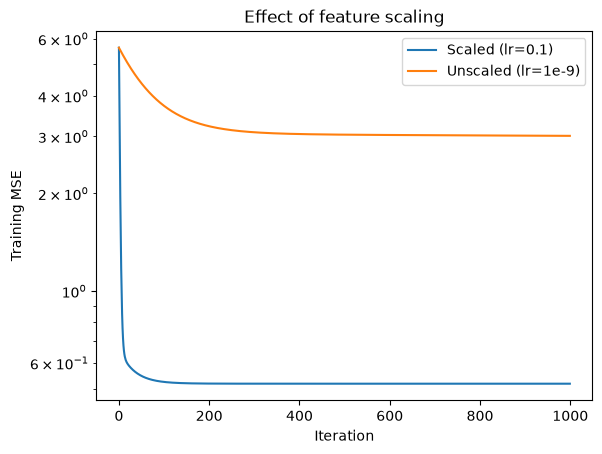

Final train MSE, scaled  : 0.517933125598221
Final train MSE, unscaled: 3.0104138277642085


In [21]:
unscaled = MyLinearRegression(lr=1e-9, n_iters=1000).fit(X_train, y_train)
scaled = MyLinearRegression(lr=0.1, n_iters=1000).fit(X_train_s, y_train)

plt.plot(scaled.loss_history, label="Scaled (lr=0.1)")
plt.plot(unscaled.loss_history, label="Unscaled (lr=1e-9)")
plt.yscale("log")
plt.xlabel("Iteration"); plt.ylabel("Training MSE")
plt.title("Effect of feature scaling")
plt.legend(); plt.show()

print("Final train MSE, scaled  :", scaled.loss_history[-1])
print("Final train MSE, unscaled:", unscaled.loss_history[-1])

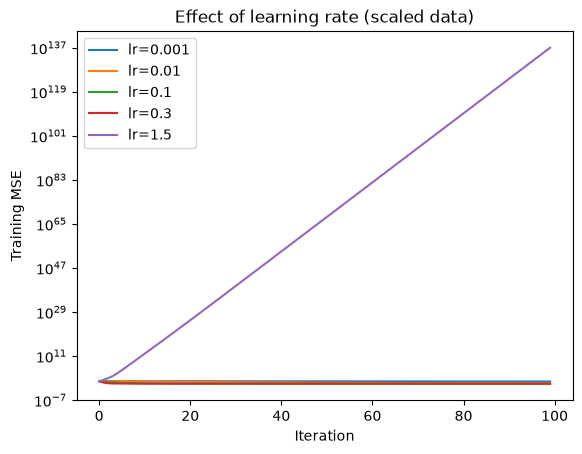

In [20]:
with np.errstate(all="ignore"):
    for lr in [0.001, 0.01, 0.1, 0.3, 1.5]:
        m = MyLinearRegression(lr=lr, n_iters=100).fit(X_train_s, y_train)
        plt.plot(m.loss_history, label=f"lr={lr}")

plt.yscale("log")
plt.xlabel("Iteration"); plt.ylabel("Training MSE")
plt.title("Effect of learning rate (scaled data)")
plt.legend(); plt.show()

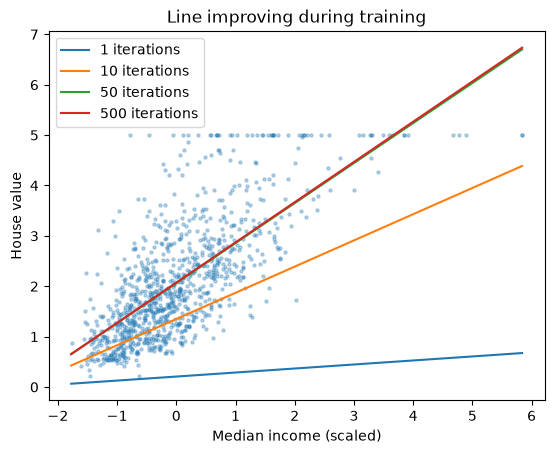

In [24]:
Xi = X_train_s[:, [0]]   # just MedInc
plt.scatter(Xi[:1000], y_train[:1000], s=5, alpha=0.3)
xs = np.linspace(Xi.min(), Xi.max(), 100).reshape(-1, 1)

for iters in [1, 10, 50, 500]:
    m = MyLinearRegression(lr=0.05, n_iters=iters).fit(Xi, y_train)
    plt.plot(xs, m.predict(xs), label=f"{iters} iterations")

plt.xlabel("Median income (scaled)"); plt.ylabel("House value")
plt.title("Line improving during training")
plt.legend(); plt.show()

In [25]:
import pandas as pd
print(pd.DataFrame({
    "feature": data.feature_names,
    "mine": mine.w,
    "sklearn": sk.coef_,
}))
print("bias  mine:", mine.b, " sklearn:", sk.intercept_)

      feature      mine   sklearn
0      MedInc  0.854383  0.854383
1    HouseAge  0.122546  0.122546
2    AveRooms -0.294410 -0.294410
3   AveBedrms  0.339259  0.339259
4  Population -0.002308 -0.002308
5    AveOccup -0.040829 -0.040829
6    Latitude -0.896929 -0.896929
7   Longitude -0.869842 -0.869842
bias  mine: 2.0719469373786192  sklearn: 2.071946937378619
